# MIMICS diversification baselines (PyTorch)

**Purpose:** establish a reproducible effectiveness baseline before researching a new reranker. The notebook compares original SERP order, dense relevance ranking, and MMR across several fixed values of \(\lambda\), then evaluates intent coverage and ranking latency.

**Run order:** execute every cell from top to bottom. If the processed MIMICS files are not available, the notebook runs a deterministic synthetic smoke test so code paths can be checked. Synthetic output is explicitly marked and must **never** be reported as research evidence.

**Important dataset caveat:** the public `MIMICS-Diversification` preprocessing script creates its document–intent labels using a keyword-matching rule. Treat those judgments as weak labels. Before claiming general improvement, validate the result on an established diversity benchmark such as the TREC Web Track, subject to access to its collection and judgments.

**Runtime:** Colab is convenient for the first run; CPU ranking is the default for latency measurements because these MIMICS candidate lists are tiny. The sentence-transformer encoder uses CUDA when available. Set `FAST_DEV_RUN = False` only after a successful small run.

In [1]:
%pip -q install sentence-transformers scikit-learn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


d:\01 Work\13-research-MaxMarginalRelevance\.venv\Scripts\python.exe: No module named pip


# 0. Initial Setup

In [2]:
! uv pip install seaborn
import seaborn as sns

Using Python 3.13.3 environment at: D:\01 Work\13-research-MaxMarginalRelevance\.venv
Audited 1 package in 43ms


In [3]:
from __future__ import annotations

import json
import os
import pickle
import platform
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split

In [4]:

sns.set_theme(
    style="darkgrid",
    context="talk",
    font_scale=0.85
)

In [5]:
SEED = 42
FAST_DEV_RUN = True            # False for the full processed train/test splits
MAX_TRAIN_QUERIES = 250        # used only when FAST_DEV_RUN=True
MAX_TEST_QUERIES = 120         # used only when FAST_DEV_RUN=True
MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
EMBEDDING_DEVICE = "auto"      # auto/cpu/cuda; model embeddings are cached on CPU
RANKING_DEVICE = "cpu"         # CPU is usually better for tiny top-10 lists
TOP_K_VALUES = (5, 10)
ALPHA = 0.5
LAMBDA_VALUES = (0.30, 0.50, 0.65, 0.80, 0.90)

In [6]:



def find_project_root(start: Path) -> Path:
    """Locate the directory containing the rerank_paper package."""
    start = start.resolve()
    candidates = [start, *start.parents]
    for candidate in candidates:
        if (candidate / "rerank_paper" / "core.py").is_file():
            return candidate
        try:
            children = list(candidate.iterdir())
        except (PermissionError, OSError):
            children = []
        for child in children:
            if child.is_dir() and (child / "rerank_paper" / "core.py").is_file():
                return child
    raise FileNotFoundError(
        "Could not find rerank_paper/core.py. Extract reranking_research_starter.zip first."
    )


PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from rerank_paper.core import (
    aggregate_metrics,
    benchmark_ranker,
    encode_records,
    evaluate_rankings,
    load_mimics_records,
    make_synthetic_encoded_queries,
    mmr_ranking,
    rank_by_relevance,
    rank_original_serp,
    set_reproducibility,
    to_device,
)

set_reproducibility(SEED)
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
print({
    "project_root": str(PROJECT_ROOT),
    "python": platform.python_version(),
    "pytorch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
})

{'project_root': 'D:\\01 Work\\13-research-MaxMarginalRelevance', 'python': '3.13.3', 'pytorch': '2.11.0+cu128', 'cuda_available': True, 'gpu_name': 'NVIDIA GeForce RTX 3050 Laptop GPU'}


# 1. Locate and load the processed MIMICS data

The loader expects `serps.pkl`, `id2doc.pkl`, `query2qid.json`, `judgement.tsv`, and the official `train_qids.npy` / `test_qids.npy` split files. It does not silently treat raw TSV or SERP files as processed data.

If the files are absent, you can still complete a synthetic smoke test. To run the real experiment, follow the upstream preparation instructions: [MIMICS-Diversification README](https://github.com/DengZhirui/MIMICS-Diversification). Its `process_mimics.py` currently contains local absolute paths for the MIMICS TSV and SERP JSONL, so edit those paths for your environment before executing that script.

In [7]:
PROJECT_ROOT

WindowsPath('D:/01 Work/13-research-MaxMarginalRelevance')

In [8]:
def find_processed_data_dir(project_root: Path) -> Path | None:
    """Find a directory containing the core processed MIMICS files."""
    required = {"serps.pkl", "id2doc.pkl", "query2qid.json", "judgement.tsv"}
    candidates = [
        project_root / "MIMICS-Diversification" / "data",
        project_root / "data",
        project_root.parent / "MIMICS-Diversification" / "data",
        Path("/content/MIMICS-Diversification/data"),
        Path("/content/data"),
    ]
    for candidate in candidates:
        if candidate.is_dir() and required.issubset({p.name for p in candidate.iterdir()}):
            return candidate.resolve()
    return None

In [9]:
# Try cloning the public processing repository once if it is not already present.
# The raw MIMICS/SERP data may still need to be downloaded and processed separately.
UPSTREAM_REPO_DIR = PROJECT_ROOT / "MIMICS-Diversification"
if not UPSTREAM_REPO_DIR.exists():
    print(f"Attempting to clone upstream repository into {UPSTREAM_REPO_DIR}...")
    try:
        clone_result = subprocess.run(
            ["git", "clone", "--depth", "1",
             "https://github.com/DengZhirui/MIMICS-Diversification.git",
             str(UPSTREAM_REPO_DIR)],
            capture_output=True, text=True, timeout=25, check=False,
        )
        if clone_result.returncode != 0:
            print("Repository clone unavailable; continuing with configured local data/smoke test.")
    except (OSError, subprocess.TimeoutExpired) as exc:
        print(f"Could not clone upstream repository ({exc}); continuing with local data/smoke test.")

DATA_DIR = find_processed_data_dir(PROJECT_ROOT)
MIMICS_AVAILABLE = DATA_DIR is not None

if MIMICS_AVAILABLE:
    train_limit = MAX_TRAIN_QUERIES if FAST_DEV_RUN else None
    test_limit = MAX_TEST_QUERIES if FAST_DEV_RUN else None
    train_records = load_mimics_records(DATA_DIR, split="train", max_queries=train_limit)
    test_records = load_mimics_records(DATA_DIR, split="test", max_queries=test_limit)
    print(f"Loaded real MIMICS data from: {DATA_DIR}")
    print(f"Train queries: {len(train_records):,}; test queries: {len(test_records):,}")
else:
    print("Processed MIMICS files not found. Running synthetic smoke test only.")
    print("For research results, prepare the real files and rerun with DATA_DIR discovered.")
    synthetic = make_synthetic_encoded_queries(
        n_queries=160 if FAST_DEV_RUN else 220,
        n_candidates=10,
        embedding_dim=64,
        n_intents=5,
        seed=SEED,
    )
    all_items = list(synthetic.values())
    train_encoded = {item.record.qid: item for item in all_items[:100]}
    test_encoded = {item.record.qid: item for item in all_items[100:]}
    DATA_MODE = "synthetic_smoke_test"

Loaded real MIMICS data from: D:\01 Work\13-research-MaxMarginalRelevance\MIMICS-Diversification\data
Train queries: 250; test queries: 120


In [10]:
# Encode the real text if the processed dataset exists; otherwise use the
# already generated deterministic toy embeddings from the previous cell.
if MIMICS_AVAILABLE:
    DATA_MODE = "mimics_weak_labels"
    start_time = time.perf_counter()
    train_encoded_cpu = encode_records(
        train_records, model_name=MODEL_NAME, batch_size=64,
        device=EMBEDDING_DEVICE, show_progress_bar=True,
    )
    test_encoded_cpu = encode_records(
        test_records, model_name=MODEL_NAME, batch_size=64,
        device=EMBEDDING_DEVICE, show_progress_bar=True,
    )
    embedding_wall_seconds = time.perf_counter() - start_time
else:
    train_encoded_cpu = train_encoded
    test_encoded_cpu = test_encoded
    embedding_wall_seconds = 0.0

d:\01 Work\13-research-MaxMarginalRelevance\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1026 17:53:23.380000 25056 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Batches: 100%|██████████| 2/2 [00:00<00:00, 86.19it/s]


In [11]:
# Keep vectors on CPU by default. For an optional GPU ranking benchmark, move
# the same cached vectors to CUDA before timing; do not include transfer time.
train_encoded = to_device(train_encoded_cpu, RANKING_DEVICE)
test_encoded = to_device(test_encoded_cpu, RANKING_DEVICE)

# Query-level internal validation split: tune MMR lambda here, never on the final test set.
all_train_qids = sorted(train_encoded.keys())
if len(all_train_qids) >= 10:
    _, validation_qids = train_test_split(
        all_train_qids, test_size=0.20, random_state=SEED, shuffle=True
    )
else:
    # Tiny synthetic smoke test only; retain at least one validation query.
    validation_qids = all_train_qids[max(1, int(0.8 * len(all_train_qids))):]
    if not validation_qids:
        validation_qids = all_train_qids[-1:]
validation_encoded = {qid: train_encoded[qid] for qid in validation_qids}

with (ARTIFACT_DIR / "train_encoded_cpu.pkl").open("wb") as f:
    pickle.dump(train_encoded_cpu, f, protocol=pickle.HIGHEST_PROTOCOL)
with (ARTIFACT_DIR / "test_encoded_cpu.pkl").open("wb") as f:
    pickle.dump(test_encoded_cpu, f, protocol=pickle.HIGHEST_PROTOCOL)

In [12]:
metadata = {
    "data_mode": DATA_MODE,
    "mimics_data_dir": str(DATA_DIR) if MIMICS_AVAILABLE else None,
    "model_name": MODEL_NAME if MIMICS_AVAILABLE else "deterministic synthetic vectors",
    "embedding_device_requested": EMBEDDING_DEVICE,
    "ranking_device": RANKING_DEVICE,
    "embedding_wall_seconds": embedding_wall_seconds,
    "n_train_queries": len(train_encoded),
    "n_test_queries": len(test_encoded),
    "fast_dev_run": FAST_DEV_RUN,
    "seed": SEED,
    "torch_version": torch.__version__,
}
with (ARTIFACT_DIR / "run_metadata.json").open("w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

train_candidate_counts = [len(item.record.candidate_ids) for item in train_encoded.values()]
test_candidate_counts = [len(item.record.candidate_ids) for item in test_encoded.values()]
print(json.dumps(metadata, indent=2))
print(f"Mean candidate count — train: {np.mean(train_candidate_counts):.2f}; test: {np.mean(test_candidate_counts):.2f}")

{
  "data_mode": "mimics_weak_labels",
  "mimics_data_dir": "D:\\01 Work\\13-research-MaxMarginalRelevance\\MIMICS-Diversification\\data",
  "model_name": "sentence-transformers/all-MiniLM-L6-v2",
  "embedding_device_requested": "auto",
  "ranking_device": "cpu",
  "embedding_wall_seconds": 15.59701449999966,
  "n_train_queries": 250,
  "n_test_queries": 120,
  "fast_dev_run": true,
  "seed": 42,
  "torch_version": "2.11.0+cu128"
}
Mean candidate count — train: 9.09; test: 9.06


# 2. Compare ranking effectiveness

The primary intent-aware metrics are **α-nDCG** and **ERR-IA**, with intent coverage as an interpretable supplement. `nDCG-any-intent` is only a coarse relevance-preservation proxy: a document counts as relevant if any intent labels it relevant. Pairwise cosine similarity is a representation-level redundancy proxy, not a ground-truth diversity metric.

All ranking methods receive the same candidate pool. `SERP order` preserves first-stage order; `Dense relevance` sorts by query/document cosine similarity; MMR uses the same embeddings for relevance and redundancy. Run all methods on the held-out split, not the train split.

In [13]:
def build_baseline_rankers(lambda_values: tuple[float, ...], top_k: int = 10):
    """Return named ranking callables with immutable parameters captured."""
    rankers = {
        "SERP order": lambda item: rank_original_serp(item),
        "Dense relevance": lambda item: rank_by_relevance(item),
    }
    for lambda_value in lambda_values:
        rankers[f"MMR lambda={lambda_value:.2f}"] = (
            lambda item, lam=lambda_value: mmr_ranking(
                item, lambda_mult=lam, top_k=top_k, candidate_depth=None,
                redundancy_floor=0.0,
            )
        )
    return rankers

In [14]:
# Hyperparameter sweep is measured only on the internal validation queries.
validation_rankers = build_baseline_rankers(LAMBDA_VALUES, top_k=max(TOP_K_VALUES))
validation_per_query = evaluate_rankings(
    validation_encoded, rankers=validation_rankers,
    k_values=TOP_K_VALUES, alpha=ALPHA,
)
validation_summary = aggregate_metrics(validation_per_query)
validation_at5 = validation_per_query[validation_per_query["k"].eq(5)].groupby("method")[
    ["alpha_ndcg", "ndcg_any_intent"]
].mean()
print("Validation set: MMR lambda sweep (use these results for configuration selection)")
display(validation_at5.round(4))

Validation set: MMR lambda sweep (use these results for configuration selection)


,alpha_ndcg,ndcg_any_intent
method,,
Dense relevance,0.3878,0.3662
MMR lambda=0.30,0.3726,0.3523
MMR lambda=0.50,0.3747,0.3505
MMR lambda=0.65,0.3674,0.3452
MMR lambda=0.80,0.3919,0.3690
MMR lambda=0.90,0.3900,0.3656
SERP order,0.4036,0.3867


In [15]:
# Predeclared selection rule: maximize alpha-nDCG@5, provided the coarse
# any-intent nDCG proxy is no more than 0.02 below dense relevance ranking.
# If no lambda meets the relevance floor, select the lambda with the best
# alpha-nDCG and clearly report that the floor was infeasible.
RELEVANCE_NDCG_TOLERANCE = 0.02
dense_relevance_ndcg = float(validation_at5.loc["Dense relevance", "ndcg_any_intent"])
mmr_validation = validation_at5[validation_at5.index.str.startswith("MMR lambda=")].copy()
feasible_mmr = mmr_validation[
    mmr_validation["ndcg_any_intent"] >= dense_relevance_ndcg - RELEVANCE_NDCG_TOLERANCE
]
selection_pool = feasible_mmr if not feasible_mmr.empty else mmr_validation
selected_method = selection_pool.sort_values(
    ["alpha_ndcg", "ndcg_any_intent"], ascending=[False, False]
).index[0]
SELECTED_LAMBDA = float(selected_method.split("=")[-1])
print(f"Selected lambda using validation only: {SELECTED_LAMBDA:.2f}")
print(f"Validation dense relevance nDCG-any-intent@5: {dense_relevance_ndcg:.4f}")
print(f"Relevance floor feasible: {not feasible_mmr.empty}")

Selected lambda using validation only: 0.80
Validation dense relevance nDCG-any-intent@5: 0.3662
Relevance floor feasible: True


In [16]:
# Final held-out test sees only the selected configuration, not the lambda grid.
test_rankers = {
    "SERP order": lambda item: rank_original_serp(item),
    "Dense relevance": lambda item: rank_by_relevance(item),
    f"MMR selected lambda={SELECTED_LAMBDA:.2f}": lambda item: mmr_ranking(
        item, lambda_mult=SELECTED_LAMBDA, top_k=max(TOP_K_VALUES),
        candidate_depth=None, redundancy_floor=0.0,
    ),
}
per_query_results = evaluate_rankings(
    test_encoded, rankers=test_rankers,
    k_values=TOP_K_VALUES, alpha=ALPHA,
)
summary_metrics = aggregate_metrics(per_query_results)
metric_pivot = summary_metrics.pivot_table(
    index=["method", "k"], columns="metric", values="mean"
).reset_index()
print("Held-out test metrics — lambda was selected on validation, not test:", DATA_MODE)
display(metric_pivot.round(4))

if DATA_MODE == "synthetic_smoke_test":
    print("\nWARNING: validation/test numbers are synthetic software-smoke-test outputs, not empirical results. Do not cite or use them in the paper.")


Held-out test metrics — lambda was selected on validation, not test: mimics_weak_labels


metric,method,k,alpha_ndcg,err_ia,intent_coverage,mean_pairwise_cosine,ndcg_any_intent
0,Dense relevance,5,0.4105,0.1584,0.6406,0.6941,0.4033
1,Dense relevance,10,0.5263,0.1725,0.8667,0.6214,0.5701
2,MMR selected lambda=0.80,5,0.4119,0.1608,0.6401,0.6779,0.4000
3,MMR selected lambda=0.80,10,0.5285,0.1746,0.8667,0.6214,0.5700
4,SERP order,5,0.4622,0.1748,0.6542,0.6569,0.4480
5,SERP order,10,0.5705,0.1881,0.8667,0.6214,0.6046


findfont: Failed to find font weight medium for Arial, now using 400.


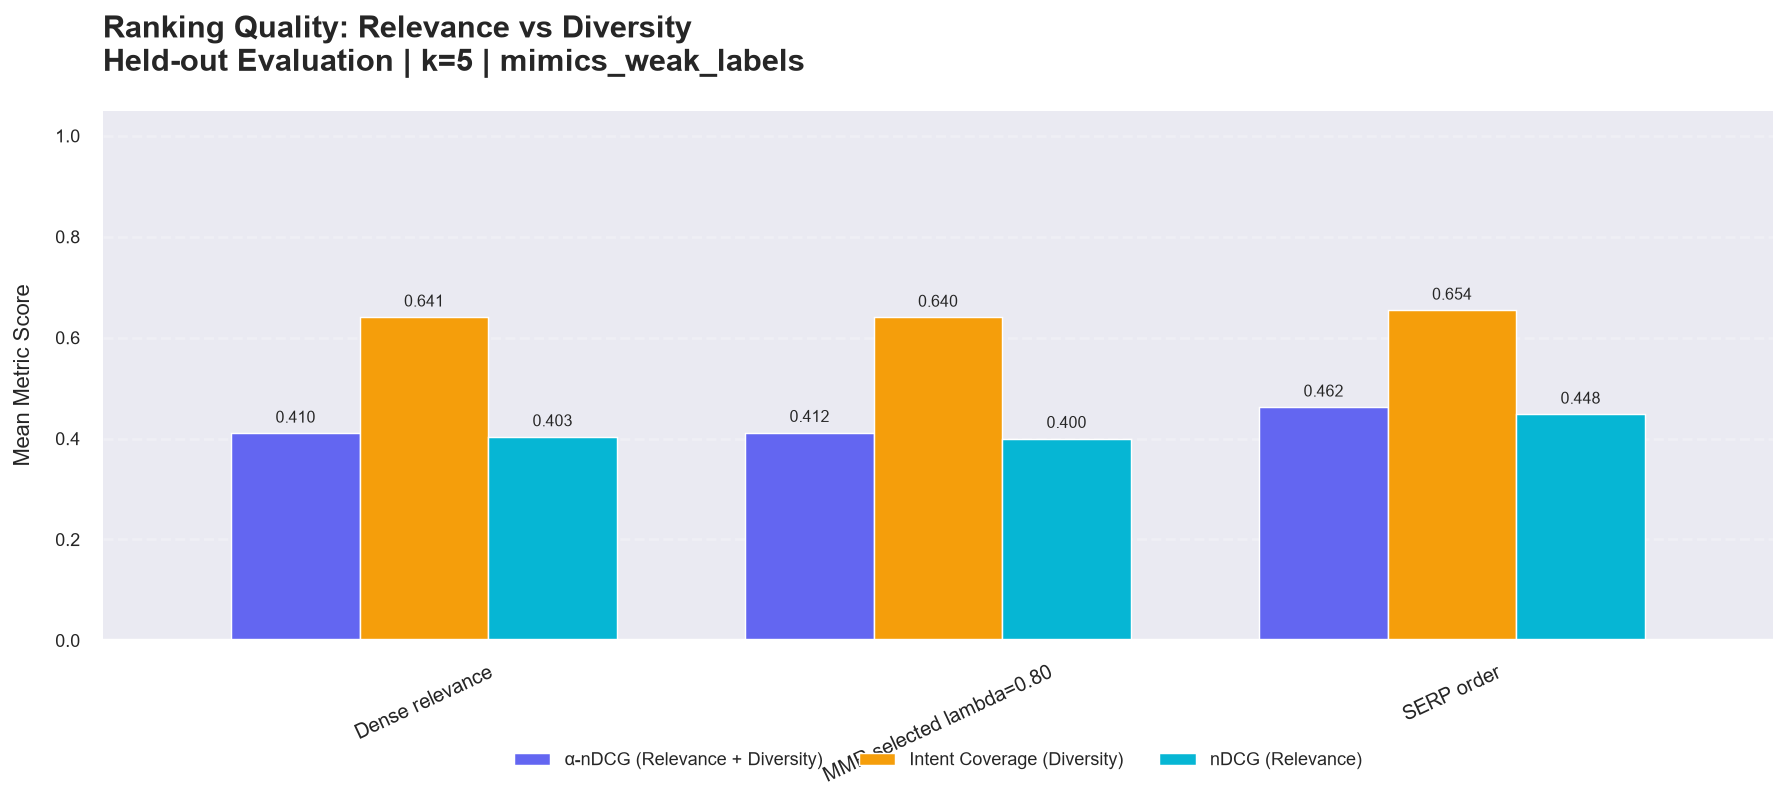

In [17]:
# 1. Prepare data
plot_data = (
    summary_metrics[
        summary_metrics["k"].eq(5)
        & summary_metrics["metric"].isin(
            ["alpha_ndcg", "ndcg_any_intent", "intent_coverage"]
        )
    ]
    .pivot(index="method", columns="metric", values="mean")
)

# Rename metrics for readability
plot_data = plot_data.rename(columns={
    "alpha_ndcg": "α-nDCG (Relevance + Diversity)",
    "ndcg_any_intent": "nDCG (Relevance)",
    "intent_coverage": "Intent Coverage (Diversity)"
})

# 3. Custom palette
colors = {
    "α-nDCG (Relevance + Diversity)": "#6366F1",  # Indigo
    "nDCG (Relevance)": "#06B6D4",                # Cyan
    "Intent Coverage (Diversity)": "#F59E0B"     # Amber
}

# 4. Plot
fig, ax = plt.subplots(figsize=(14, 6.5), dpi=130)

plot_data.plot(
    kind="bar",
    ax=ax,
    width=0.75,
    color=[colors[col] for col in plot_data.columns],
    edgecolor="white",
    linewidth=0.8
)

# 5. Value annotations
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=4,
        fontsize=9,
        fontweight="medium"
    )

# 6. Titles
ax.set_title(
    f"Ranking Quality: Relevance vs Diversity\n"
    f"Held-out Evaluation | k=5 | {DATA_MODE}",
    fontsize=17,
    fontweight="bold",
    pad=22,
    loc="left"
)

ax.set_xlabel("")
ax.set_ylabel(
    "Mean Metric Score",
    fontsize=12,
    labelpad=12
)

# 7. Axis formatting
ax.set_ylim(0, max(1.05, plot_data.max().max() * 1.15))

ax.tick_params(
    axis="x",
    rotation=25,
    labelsize=11
)

ax.tick_params(
    axis="y",
    labelsize=10
)

# 8. Grid and borders
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.grid(axis="x", visible=False)

sns.despine(
    ax=ax,
    top=True,
    right=True,
    left=True
)

# 9. Legend
ax.legend(
    title=None,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    frameon=False,
    fontsize=10
)

plt.tight_layout()
plt.show()

# 3. Benchmark ranking-only latency

This benchmark starts after query/document embeddings are available. It includes Python/PyTorch selection overhead but excludes text embedding and retrieval. Report this boundary precisely in any paper. p50/p95 can be noisy for very short operations, so use repeated calls, a fixed machine, and identical settings for all methods.

In [18]:
latency_rows = []
latency_sample = list(test_encoded.values())[: min(100, len(test_encoded))]
latency_rankers = {
    "SERP order": test_rankers["SERP order"],
    "Dense relevance": test_rankers["Dense relevance"],
    f"MMR selected lambda={SELECTED_LAMBDA:.2f}": test_rankers[f"MMR selected lambda={SELECTED_LAMBDA:.2f}"],
}
for method_name, ranker in latency_rankers.items():
    measured = benchmark_ranker(
        latency_sample, ranker, warmup_calls=3,
        repeats_per_query=10, max_queries=100,
    )
    latency_rows.append({
        "method": method_name,
        **{key: value for key, value in measured.items() if key != "latencies_ms"},
    })
latency_results = pd.DataFrame(latency_rows).sort_values("p95_ms")
display(latency_results.round(4))

if DATA_MODE == "synthetic_smoke_test":
    print("WARNING: timing is only a code-path smoke test on synthetic vectors. Do not use it as a paper result.")

,method,n_queries,n_calls,device,mean_ms,p50_ms,p95_ms,p99_ms,min_ms,max_ms,calls_per_second_serial
0,SERP order,100,1000,cpu,0.0011,0.0008,0.0020,0.0023,0.0007,0.0041,941442.2896
1,Dense relevance,100,1000,cpu,0.0131,0.0105,0.0235,0.0388,0.0099,0.1587,76111.0308
2,MMR selected lambda=0.80,100,1000,cpu,0.6221,0.6156,0.8919,1.2063,0.3306,1.6931,1607.5284


In [19]:
# Persist artifacts so Notebook 02 can reuse identical encodings and split.
validation_per_query.to_csv(ARTIFACT_DIR / "baseline_validation_lambda_sweep.csv", index=False)
validation_summary.to_csv(ARTIFACT_DIR / "baseline_validation_summary.csv", index=False)
per_query_results.to_csv(ARTIFACT_DIR / "baseline_per_query_metrics.csv", index=False)
summary_metrics.to_csv(ARTIFACT_DIR / "baseline_summary_metrics.csv", index=False)
latency_results.to_csv(ARTIFACT_DIR / "baseline_latency.csv", index=False)

metadata["selected_lambda_from_validation"] = SELECTED_LAMBDA
metadata["validation_relevance_ndcg_tolerance"] = RELEVANCE_NDCG_TOLERANCE
with (ARTIFACT_DIR / "run_metadata.json").open("w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)
print("Artifacts written to:", ARTIFACT_DIR)
print("Files:")
for path in sorted(ARTIFACT_DIR.glob("*")):
    print(f" - {path.name} ({path.stat().st_size / 1024:.1f} KiB)")

Artifacts written to: D:\01 Work\13-research-MaxMarginalRelevance\artifacts
Files:
 - .gitkeep (0.0 KiB)
 - baseline_latency.csv (0.4 KiB)
 - baseline_per_query_metrics.csv (67.7 KiB)
 - baseline_summary_metrics.csv (3.5 KiB)
 - baseline_validation_lambda_sweep.csv (61.7 KiB)
 - baseline_validation_summary.csv (7.8 KiB)
 - README.md (0.1 KiB)
 - run_metadata.json (0.5 KiB)
 - test_encoded_cpu.pkl (23743.6 KiB)
 - train_encoded_cpu.pkl (98223.1 KiB)


# 4. What these results can and cannot establish

- MIMICS supports intent-level diversification metrics, but its average candidate set is about nine and its maximum is ten. This notebook therefore does **not** establish scaling to 100–1,000 candidates.
- The repository's preprocessing uses keyword matching for document/intent labels. This creates label noise and may favor lexical overlap. Treat it as a limitation, and plan an evaluation on an independently judged benchmark.
- For a paper, repeat the final run with all official train/test queries, use a validation split for hyperparameter selection, add confidence intervals or paired tests, and run the larger-pool latency experiment in Notebook 03.